# **Feature Engineering**

**Objetivo:** Analizar cómo las características comerciales de los productos del ecosistema móvil de Falabella Perú (marca, vendedor, descuentos y volumen de reseñas) determinan su precio final.

**Propósito del notebook:**
Tomar el dataset limpio (`dataset_inicial.csv`) que conserva la dispersión real del mercado (desde accesorios económicos hasta smartphones de gama ultra-alta de S/ 12,000) y aplicar técnicas de Feature Engineering:
1. **Generación de características:** Operaciones matemáticas, indicadores de nulos, *binning* y frecuencias.
2. **Transformación de características:** Mitigación de asimetría (*skewness*) con raíz cuadrada y logaritmo, además de codificación categórica (*Label Encoding* y *One-Hot Encoding*).
3. **Escalado de características:** Normalización (`MinMaxScaler`) y Estandarización (`StandardScaler`).

# Carga de librerías y de los datos

In [54]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Cargamos el dataset limpio de la etapa anterior
df = pd.read_csv("dataset_inicial.csv")
display(df.head())
print(f"Dimensiones del dataset: {df.shape}")

,marca,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas
0,APPLE,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500
1,XIAOMI,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273
2,APPLE,IPhone 18 Pro Max 256GB,Por Falabella,6999.0,7299.0,4.11,0.0000,0,NaN
3,APPLE,IPhone 18 Pro 256GB,Por Falabella,6499.0,6699.0,2.99,0.0000,0,NaN
4,SAMSUNG,Celular Galaxy A57 5G,Por Falabella,1899.0,2299.0,17.40,4.7115,52,4.7115


Dimensiones del dataset: (1830, 9)


# Creación de variables

### **1. Generación de Características Matemáticas e Indicadores**

* **Ahorro en soles (`ahorro`):** Aunque ya contamos con el porcentaje de `descuento`, un 20% de descuento en una funda de S/ 30 no representa el mismo impacto económico que un 20% en un iPhone de S/ 6,000. Restamos el `precio_original` menos el `precio` para obtener el ahorro monetario real.
* **Indicador de producto con reseñas (`tiene_resenas`):** En la limpieza vimos que `calificacion_con_resenas` tiene 933 valores nulos (`NaN`) que corresponden a productos nuevos o "fantasmas" sin opiniones. En lugar de perder ese patrón, creamos una columna binaria (`1` si tiene reseñas, `0` si está vacío) para evaluar si el simple hecho de tener opiniones influye en el precio.

In [55]:
df["ahorro"] = df["precio_original"] - df["precio"]

# Creación de variable binaria sobre los nulos de calificacion_con_resenas
# Si es No Nulo le asignamos 1, de lo contrario 0
df["tiene_resenas"] = df["calificacion_con_resenas"].notnull() * 1

display(df.head(2))

,marca,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas,ahorro,tiene_resenas
0,APPLE,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500,530.0,1
1,XIAOMI,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273,10.0,1


### **2. Generación de Características por Agrupación (Binning)**

* **Gama del producto (`gama_precio`):** Debido a que decidimos mantener los *outliers* reales (productos hasta S/ 12,000) porque reflejan la naturaleza del catálogo completo (accesorios y celulares), necesitamos segmentar esta dispersión. Usamos `pd.cut()` para agrupar el `precio` en 4 categorías comerciales claras: `accesorio_bajo` (hasta S/ 250), `gama_media` (S/ 250 a S/ 1,500), `gama_alta` (S/ 1,500 a S/ 4,000) y `premium` (más de S/ 4,000).
* **Nivel de descuento (`nivel_descuento`):** Agrupamos el porcentaje de descuento en rangos (`sin_descuento`, `bajo`, `medio`, `alto`) para analizar las estrategias promocionales por bloques.

In [56]:
# Explorar los productos económicos para detectar dónde empiezan los smartphones reales
df_baratos = df[(df['precio'] > 0) & (df['precio'] < 600)].sort_values(by='precio')
display(df_baratos[['nombre', 'precio']].head(30))

,nombre,precio
1270,Guante Funda Manga Dedales Grip De Dedos Gamer...,7.00
352,CASE MAGSAFE TRANSPARENTE PARA IPHONE 17 PRO MAX,7.00
793,Señal de Extintor 20x30 cm.,7.90
721,Señal de Botiquín 15x22.5 cm.,7.90
1164,Señal de Prohibido el Ingreso 15x22.5 cm.,7.90
1516,Señal de Extintor Multipropósito 15x22.5 cm.,7.90
418,Funda Acuática Sumergible Protector de Agua pa...,7.99
1440,Dedales Fundas Antisudor Dedos Gamer,7.99
1462,Dedales Gamer Antisudor,8.00
1560,Convertidor Otg Lightning Adaptador a Tipo C,8.00


El accesorio con el precio más bajo es de 7 soles.

In [57]:
df_baratos_2 = df[(df['precio'] >= 280) & (df['precio'] <= 450)].sort_values(by='precio')
display(df_baratos_2[['nombre', 'precio']].head(30))

,nombre,precio
334,GIMBAL Estabilizador Soporte de Telefono Live ...,283.90
838,TELÉFONO FIJO INALÁMBRICO NEGRO KX-TG3452LCB,289.00
773,Adaptador de corriente dinámico de 40 W (máx. ...,299.00
347,Wave Beam 2 Audifono Inalámbrico con Cancelaci...,299.00
608,POWER BANK NEXODE 25000 MAH 200W PORTÁTIL PD Q...,299.90
1404,Smartphone Blade A35e 6.52 64 Gb Gris,319.00
346,AUDIFONO TUNE 770 NC BLUETOOTH NEGRO,321.90
228,Micrófono Inalámbrico UHF Dual BT-Q2M,327.90
607,Panel Solar Portatil Plegable 28w Cargador Usb...,329.90
722,Battery Pack 20000mah 45w Beige + Adaptador 45...,334.00


Como se puede observar, el primer celular registrado 'Smartphone Blade A35e 6.52 64 Gb Gris' tiene un valor de 319 soles, lo cual indica que es el celular con el precio más bajo dentro de nuestro dataset. Ahora, segmentar de 318.99 soles a más como celulares estaría mal, pues vemos que un audífono tiene el precio de 321 soles y no es un celular, sino un accesorio. De esta forma, para tratar con la superposición de precios, se realizará una calificación en base a los siguientes bins: economico, intermedio, gama_alta, premium.

In [58]:
# Clasificacion por segmento comercial
bins_precio = [0, 450, 1500, 4000, 15000]
etiquetas_precio = ["economico", "intermedio", "gama_alta", "premium"]
df["segmento_precio"] = pd.cut(df["precio"], bins=bins_precio, labels=etiquetas_precio)

# Discretización para el porcentaje de descuento
bins_desc = [-1, 0, 15, 35, 100]
etiquetas_desc = ["sin_descuento", "desc_bajo", "desc_medio", "desc_alto"]
df["nivel_desc"] = pd.cut(df["descuento"], bins=bins_desc, labels=etiquetas_desc)

# Comprobamos la distribución del catálogo
print("Distribución de los productos por segmento de precio:")
print(df["segmento_precio"].value_counts())

Distribución de los productos por segmento de precio:
segmento_precio
economico     1616
intermedio      91
gama_alta       87
premium         36
Name: count, dtype: int64


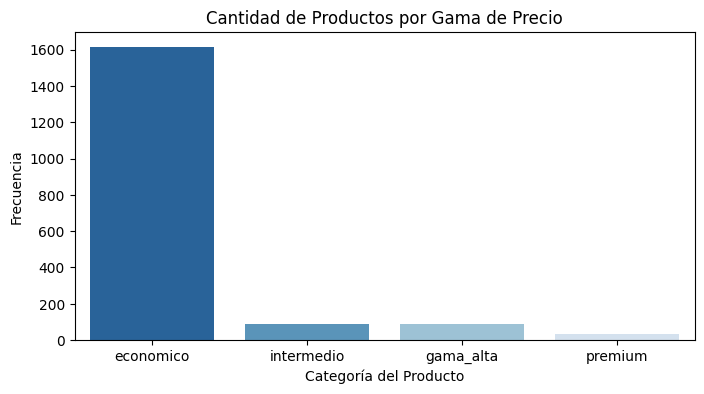

In [59]:
# Distribución de las gamas de producto
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="segmento_precio", palette="Blues_r")
plt.title("Cantidad de Productos por Gama de Precio")
plt.xlabel("Categoría del Producto")
plt.ylabel("Frecuencia")
plt.show()

## **3. Transformación de Características**

### 3.1 Transformaciones Logarítmicas (Reducción de Asimetría)
Las variables económicas (como `precio`) y de popularidad (como `cantidad_resenas`) suelen estar muy sesgadas hacia la derecha en el comercio electrónico. Aplicaremos `np.log()` para comprimir la escala y acercar su distribución a una campana normal. Sumamos `+1` a las reseñas para evitar el error matemático de calcular el logaritmo de 0.

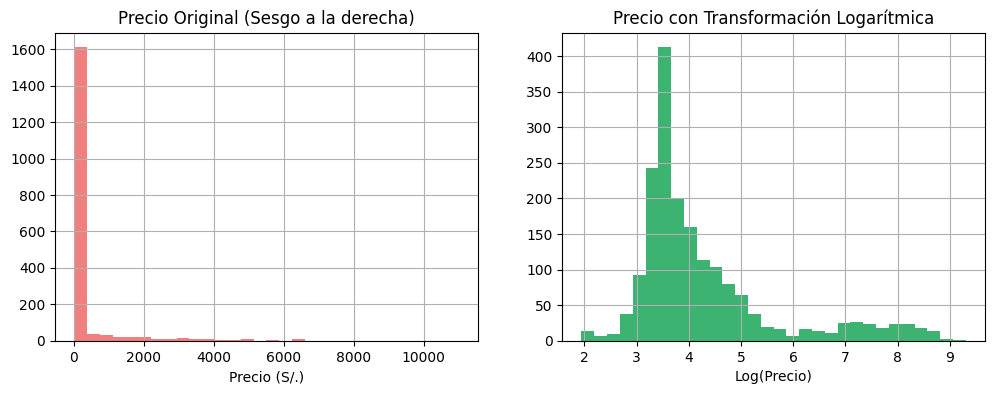

In [60]:
# Transformación logarítmica para suavizar el sesgo
df["precio_log"] = np.log(df["precio"])
df["resenas_log"] = np.log(df["cantidad_resenas"] + 1)

# Visualización del efecto de la transformación en el Precio
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df["precio"].hist(bins=30, color="lightcoral")
plt.title("Precio Original (Sesgo a la derecha)")
plt.xlabel("Precio (S/.)")

plt.subplot(1, 2, 2)
df["precio_log"].hist(bins=30, color="mediumseagreen")
plt.title("Precio con Transformación Logarítmica")
plt.xlabel("Log(Precio)")
plt.show()

La transformación aplicada no busca forzar una simetría perfecta, sino comprimir la escala de precios para estabilizar los modelos matemáticos. Esta gráfica resultante refleja la verdadera estructura del catálogo: el enorme pico izquierdo concentra el volumen masivo de accesorios económicos, mientras que la extensión derecha agrupa a los smartphones. Forzar una campana de Gauss perfecta implicaría distorsionar y perder la naturaleza comercial de nuestros datos.

### 3.2 Codificación de Variables Categóricas (Encoding)
Para que los algoritmos procesen los textos (`marca`, `vendedor`, `segmento_precio`), debemos convertirlos a números:
1. **Frecuencias (`vendedor_count`, `marca_freq`):** Calculamos cuántas veces aparece un vendedor o marca para medir su peso en el catálogo.
2. **Agrupación de marcas pequeñas (`marca_limpia`):** Marcas con menos de 10 productos se agrupan en `"otra_marca"` para evitar exceso de columnas ruidosas.
3. **Mapeo Ordinal:** Asignamos valores (0 a 3) a `segmento_precio` respetando su jerarquía de valor.
4. **One-Hot Encoding (`pd.get_dummies`):** Convertimos `marca_limpia` y `nivel_desc` en variables binarias (0 y 1).

In [61]:
# Frecuencias comerciales
df["vendedor_count"] = df["vendedor"].map(df["vendedor"].value_counts())
df["marca_count"] = df["marca"].map(df["marca"].value_counts())
df["marca_freq"] = round(df["marca"].map(df["marca"].value_counts(normalize=True)), 4)

# Agrupación y estilización de marcas
marcas_frecuentes = df["marca"].value_counts()[df["marca"].value_counts() >= 10].index
df["marca_limpia"] = df["marca"].apply(lambda x: x if x in marcas_frecuentes else "otra_marca")
df["marca_limpia"] = df["marca_limpia"].str.capitalize() # Deja los nombres como 'Apple', 'Xiaomi'

# Estilización de los niveles de descuento
mapeo_desc_corto = {
    "sin_descuento": "sin_desc",
    "desc_bajo": "bajo",
    "desc_medio": "medio",
    "desc_alto": "alto"
}
df["nivel_desc_corto"] = df["nivel_desc"].map(mapeo_desc_corto)

# Jerarquía de precios
mapeo_precio = {"economico": 0, "intermedio": 1, "gama_alta": 2, "premium": 3}
df["segmento_precio_num"] = df["segmento_precio"].map(mapeo_precio).astype(int)

# Generación de Dummies con nombres limpios
df_dummies = pd.get_dummies(df[["marca_limpia", "nivel_desc_corto"]], prefix=["marca", "nivel_desc"], dtype=int)


df_final = pd.concat([df, df_dummies], axis=1)

print("Nuevas columnas generadas:")
print(df_dummies.columns.tolist())

Nuevas columnas generadas:
['marca_Apple', 'marca_Belkin', 'marca_Case', 'marca_Generico', 'marca_Hoco', 'marca_Honor', 'marca_Ldnio', 'marca_Memo', 'marca_Motorola', 'marca_Nillkin', 'marca_Oem', 'marca_Otra_marca', 'marca_Ringke', 'marca_Samsung', 'marca_Seisa', 'marca_Shield', 'marca_Space', 'marca_Ugreen', 'marca_Xiaomi', 'nivel_desc_sin_desc', 'nivel_desc_bajo', 'nivel_desc_medio', 'nivel_desc_alto']


- Contamos cuántas veces aparece un vendedor y una marca en el dataset.
- Filtramos el número de frecuencias de una marca, en caso aparezca menos de 10 veces se denominará como 'otra_marca'.
- Creamos un diccionario con las categorías de precios con un valor numérico que indica la jerarquía de precios.
- Convertimos marca_limpia y nivel_desc a binario usando get_dummies, pues simplemente buscamos una forma de identificarlos, mas no de tener un orden sobre ellos.

Sobre la tabla:
- El registro 0 es un producto APPLE que pertenece al segmento 1 (intermedio) y es comercializado por un vendedor que tiene una oferta total de 18 productos en la plataforma.   
- Los registros 2 y 3 también son APPLE, pero pertenecen al segmento 3 (premium) y son ofrecidos por un vendedor de mayor volumen (con 35 productos en su catálogo).   
- El registro 1 es un producto XIAOMI clasificado como 0 (económico), vendido por una entidad con 14 productos.

En términos comerciales, Apple vende producos de mayor precio, lo que indica que su público objetivo son personas con una mayor estabilidad económica. En cambio, Xiaomi es practicamente lo opuesto, pues su ganancia se base en el mercado por volumen, es decir que su estrategia comercial se enfoca en precios a bajo costo.

## **4. Escalado de Características (Feature Scaling)**

Las variables tienen rangos muy distintos (el precio llega a miles, la calificación de 0 a 5). Para evitar que los modelos se sesguen por la magnitud de los números, aplicamos:
* **MinMaxScaler:** Escala los valores proporcionalmente entre 0 y 1.
* **StandardScaler:** Centra los datos (media = 0) y ajusta la desviación estándar a 1.

In [62]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Columnas numéricas clave a escalar
cols_numericas = ["precio", "ahorro", "descuento", "calificacion", "cantidad_resenas", "vendedor_count"]
df_num = df_final[cols_numericas]

# Escalamiento Min-Max (0 a 1)
scaler_mm = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_mm.fit_transform(df_num), columns=cols_numericas)
print("______Estadísticas MinMaxScaler (Rango 0 a 1)______")
display(df_minmax.describe().round(3))

# Escalamiento StandardScaler (Media 0, Std 1)
scaler_ss = StandardScaler()
df_standard = pd.DataFrame(scaler_ss.fit_transform(df_num), columns=cols_numericas)
print("\\n_____Estadísticas StandardScaler (Media 0, Std 1)_____")
display(df_standard.describe().round(3))


______Estadísticas MinMaxScaler (Rango 0 a 1)______


,precio,ahorro,descuento,calificacion,cantidad_resenas,vendedor_count
count,1830.000,1830.000,1830.000,1830.000,1830.000,1830.000
mean,0.030,0.025,0.489,0.422,0.002,0.199
std,0.088,0.082,0.231,0.452,0.027,0.349
min,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.002,0.004,0.334,0.000,0.000,0.017
50%,0.003,0.006,0.521,0.000,0.000,0.052
75%,0.008,0.010,0.639,0.935,0.000,0.111
max,1.000,1.000,1.000,1.000,1.000,1.000


\n_____Estadísticas StandardScaler (Media 0, Std 1)_____


,precio,ahorro,descuento,calificacion,cantidad_resenas,vendedor_count
count,1830.000,1830.000,1830.000,1830.000,1830.000,1830.000
mean,-0.000,0.000,0.000,-0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-0.340,-0.305,-2.115,-0.933,-0.076,-0.570
25%,-0.313,-0.261,-0.670,-0.933,-0.076,-0.520
50%,-0.303,-0.235,0.139,-0.933,-0.076,-0.421
75%,-0.245,-0.177,0.649,1.135,-0.061,-0.252
max,11.025,11.949,2.209,1.278,37.200,2.295


Aplicamos ambos escalados porque las variables tienen magnitudes muy distintas (precios en miles frente a calificaciones hasta 5). MinMaxScaler lleva los datos a un rango estricto de 0 a 1, mientras que StandardScaler centra los valores con media cero, un requisito obligatorio para poder aplicar PCA. Generar ambos formatos asegura que el dataset esté completamente preparado para cualquier algoritmo de modelamiento.

## **5. Extracción de Características (PCA) y Exportación**

Aplicamos Análisis de Componentes Principales (PCA) sobre las variables estandarizadas para entender cuántos componentes logran resumir la mayor parte de la información (varianza) del mercado de teléfonos en Falabella. Finalmente, limpiamos las columnas auxiliares y exportamos el dataset.

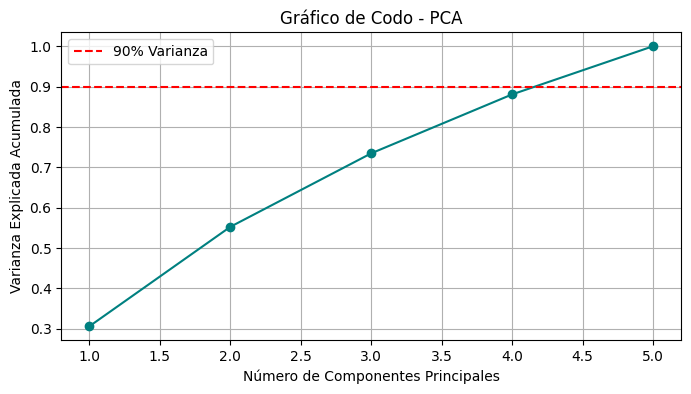

In [63]:
from sklearn.decomposition import PCA

# Seleccionamos variables predictoras estandarizadas
X = df_standard.drop(columns=["precio"])


pca = PCA()
pca.fit(X)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

# Gráf. Codo
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", color="teal")
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Varianza')
plt.xlabel("Número de Componentes Principales")
plt.ylabel("Varianza Explicada Acumulada")
plt.title("Gráfico de Codo - PCA")
plt.legend()
plt.grid(True)
plt.show()

- La línea de varianza explicada acumulada crece de forma casi constante, sin mostrar un "codo" o quiebre abrupto en los primeros puntos.   
- Al usar 4 componentes principales, el modelo logra capturar aproximadamente el 88% de la información total, quedando muy cerca pero por debajo de la línea roja que marca el umbral del 90%.  
- Para alcanzar el 100% de la varianza y superar el umbral exigido, es necesario utilizar los 5 componentes completos.

En otras palabras, el hecho de que necesitemos casi todos los componentes para llegar al 90% significa que nuestras variables aportan información única y poco redundante. No podemos comprimir el comportamiento de los productos de Falabella a solo 1 o 2 dimensiones sin perder detalles cruciales sobre cómo el vendedor, los descuentos y la marca afectan el precio final.

In [64]:
# Limpiamos columnas de texto redundantes o auxiliares antes de exportar
columnas_a_borrar = [
    "marca",
    "marca_limpia",
    "segmento_precio",
    "nivel_desc",
    "nivel_desc_corto"
]
df_final.drop(columns=columnas_a_borrar, inplace=True, errors="ignore")

# Exportamos el dataset enriquecido y totalmente numérico/codificado
df_final.to_csv("dataset_feature_engineering.csv", index=False, encoding="utf-8-sig")
print("Dimensiones del dataset final:", df_final.shape)
print("Dataset final guardado exitosamente como 'dataset_feature_engineering.csv'")

Dimensiones del dataset final: (1830, 39)
Dataset final guardado exitosamente como 'dataset_feature_engineering.csv'


In [65]:
display(df_final.head(2))
print(df_final.shape)
print(df_final.columns)

,nombre,vendedor,precio,precio_original,descuento,calificacion,cantidad_resenas,calificacion_con_resenas,ahorro,tiene_resenas,...,marca_Samsung,marca_Seisa,marca_Shield,marca_Space,marca_Ugreen,marca_Xiaomi,nivel_desc_sin_desc,nivel_desc_bajo,nivel_desc_medio,nivel_desc_alto
0,IPhone 14 128GB Morado Reacondicionado A2649,Por Electronic Deals Pe,1469.0,1999.0,26.51,4.2500,4,4.2500,530.0,1,...,0,0,0,0,0,0,0,0,1,0
1,Batería externa Power Bank 20000mAh Integrated...,Por Xiaomi Tienda Oficial,79.0,89.0,11.24,4.7273,22,4.7273,10.0,1,...,0,0,0,0,0,1,0,1,0,0


(1830, 39)
Index(['nombre', 'vendedor', 'precio', 'precio_original', 'descuento',
       'calificacion', 'cantidad_resenas', 'calificacion_con_resenas',
       'ahorro', 'tiene_resenas', 'precio_log', 'resenas_log',
       'vendedor_count', 'marca_count', 'marca_freq', 'segmento_precio_num',
       'marca_Apple', 'marca_Belkin', 'marca_Case', 'marca_Generico',
       'marca_Hoco', 'marca_Honor', 'marca_Ldnio', 'marca_Memo',
       'marca_Motorola', 'marca_Nillkin', 'marca_Oem', 'marca_Otra_marca',
       'marca_Ringke', 'marca_Samsung', 'marca_Seisa', 'marca_Shield',
       'marca_Space', 'marca_Ugreen', 'marca_Xiaomi', 'nivel_desc_sin_desc',
       'nivel_desc_bajo', 'nivel_desc_medio', 'nivel_desc_alto'],
      dtype='object')


# Conclusión del notebook de feature engineering

- Identificación del Valor de Marca (Brand Premium): Al separar marca_Apple o marca_Xiaomi en columnas independientes, el modelo de correlación podrá medir exactamente cuántos soles extra paga el consumidor únicamente por el logotipo impreso en el producto, aislando ese efecto de las especificaciones técnicas del equipo.

- Influencia del Tamaño del Vendedor: La variable matemática vendedor_count revela si existe un monopolio de precios. Permite analizar si las tiendas oficiales con inventarios gigantescos (como Falabella) manejan precios más agresivos o más costosos en comparación con los pequeños vendedores del Marketplace que buscan competir.

- Estrategia Promocional por Bloques: Con las columnas nivel_desc_alto o nivel_sin_desc, podemos cruzar los datos para descubrir la política de descuentos. Esto resuelve la incógnita de si las rebajas fuertes (ej. Cyber Wow) se aplican masivamente para liquidar la gama media (segmento_precio_num = 1), mientras que los equipos de gama premium son inelásticos (no bajan de precio).

- El Peso de la Validación Social: Las variables resenas_log y tiene_resenas traducen la interacción humana a números. Esto ayuda a responder si un alto volumen de opiniones empuja el precio hacia arriba (por alta demanda) o si, por el contrario, los productos de mayor precio del catálogo exhiben menos reseñas debido a su exclusividad y bajo nivel de rotación.